In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
laptops = pd.read_csv('final4_laptop.csv')
laptops.head()

,Unnamed: 0.1,Unnamed: 0,category,cores,threads,base_clock_ghz,tdp_w,l2_cache_mb,l3_cache_mb,cpu_mark,years_ago,manufacturer_Apple,manufacturer_Intel,manufacturer_Other,manufacturer_Qualcomm,specs_missing_count
0,2,9,Laptop,4,8.0,2.4,47.0,1.000,6.0,5566,13,0,1,0,0,0
1,3,12,Laptop,2,2.0,2.0,31.0,1.000,2.0,645,17,0,0,0,0,1
2,4,13,Laptop,1,1.0,1.2,9.0,0.125,0.0,112,15,0,0,1,0,2
3,5,14,Laptop,2,2.0,1.3,10.0,3.000,1.0,536,17,0,1,0,0,1
4,6,16,Laptop,1,1.0,0.8,28.6,1.000,0.5,67,17,0,1,0,0,3


In [3]:
laptops_new = laptops[laptops['years_ago'] <= 5]

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


def plot_qq(df, columns=None, log_columns=None, title=None):
    """
    Строит Q-Q plots для выбранных колонок DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        Исходный датасет.

    columns : list[str] | None
        Колонки, для которых нужно построить Q-Q plot.
        Если None, используются все числовые колонки.

    log_columns : list[str] | None
        Колонки, которые нужно преобразовать через log1p(x)
        перед построением Q-Q plot.

    Notes
    -----
    - Бинарные признаки автоматически пропускаются.
    - Колонки с <= 2 уникальными значениями не строятся.
    - Для логарифмируемых колонок используется np.log1p(x).
    - Исходный DataFrame не изменяется.
    """

    if columns is None:
        columns = df.select_dtypes(include=np.number).columns.tolist()

    if log_columns is None:
        log_columns = []

    # Проверка существования колонок
    missing_columns = [
        col for col in columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"В DataFrame нет колонок: {missing_columns}"
        )

    missing_log_columns = [
        col for col in log_columns
        if col not in columns
    ]

    if missing_log_columns:
        raise ValueError(
            "log_columns должны входить в columns. "
            f"Не найдены среди columns: {missing_log_columns}"
        )

    # Оставляем только небинарные признаки
    qq_columns = [
        col for col in columns
        if df[col].dropna().nunique() > 2
    ]

    skipped_binary = [
        col for col in columns
        if df[col].dropna().nunique() <= 2
    ]

    print("Q-Q plots будут построены для:")
    print(qq_columns)

    if skipped_binary:
        print("\nПропущены бинарные/константные признаки:")
        print(skipped_binary)

    for col in qq_columns:
        values = df[col].dropna().astype(float)

        label = col

        if col in log_columns:
            if (values < -1).any():
                print(
                    f"Пропуск {col}: "
                    "log1p нельзя применять к значениям < -1."
                )
                continue

            values = np.log1p(values)
            label = f"log1p({col})"

        plt.figure(figsize=(7, 6))

        stats.probplot(
            values,
            dist="norm",
            plot=plt
        )
        if title is None:
            plt.title(f"Q-Q plot: {label}")
        else:
            plt.title(title)
        plt.xlabel(
            "Теоретические квантили нормального распределения"
        )
        plt.ylabel(
            f"Наблюдаемые значения: {label}"
        )

        plt.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.show()

In [5]:
laptops.columns.shape

(16,)

In [6]:
laptops.drop(['Unnamed: 0.1', 'Unnamed: 0'], axis=1, inplace=True)


In [7]:
numeric = laptops.select_dtypes(include='number').columns
numeric.shape

(13,)

Q-Q plots будут построены для:
['cpu_mark']


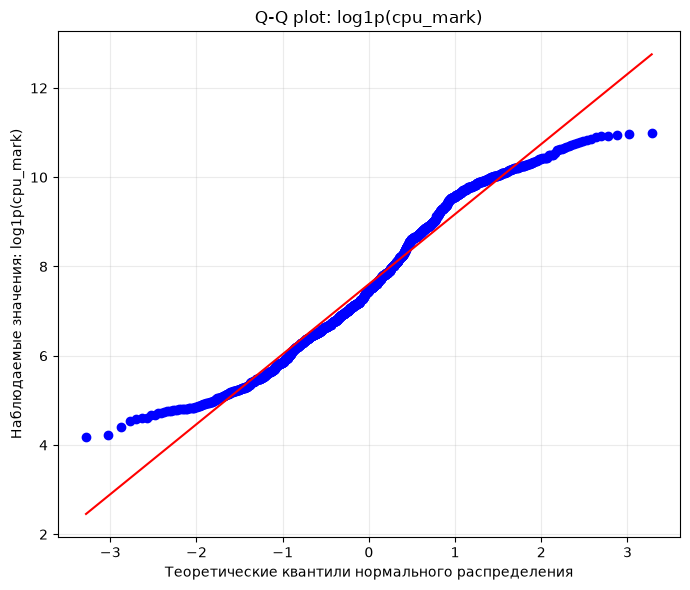

In [8]:
plot_qq(
    laptops,
    columns=[
        'cpu_mark'
    ],
    log_columns=[
        "cpu_mark"
    ]
)

Q-Q plots будут построены для:
['cpu_mark']


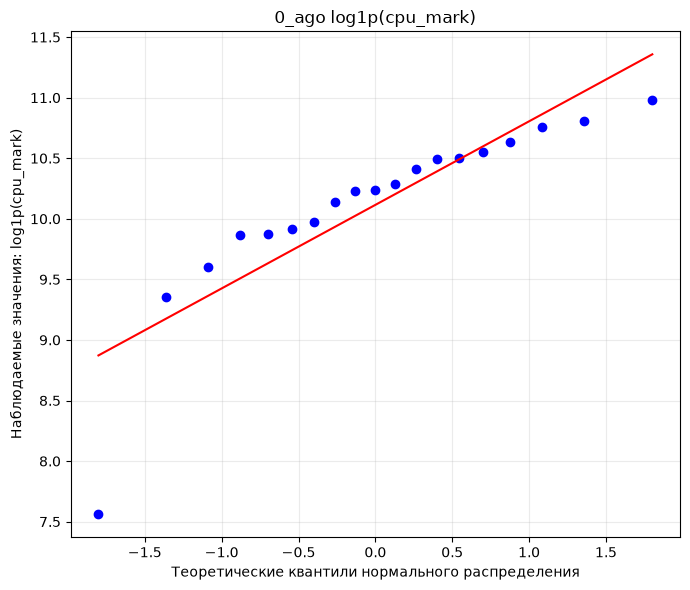

Q-Q plots будут построены для:
['cpu_mark']


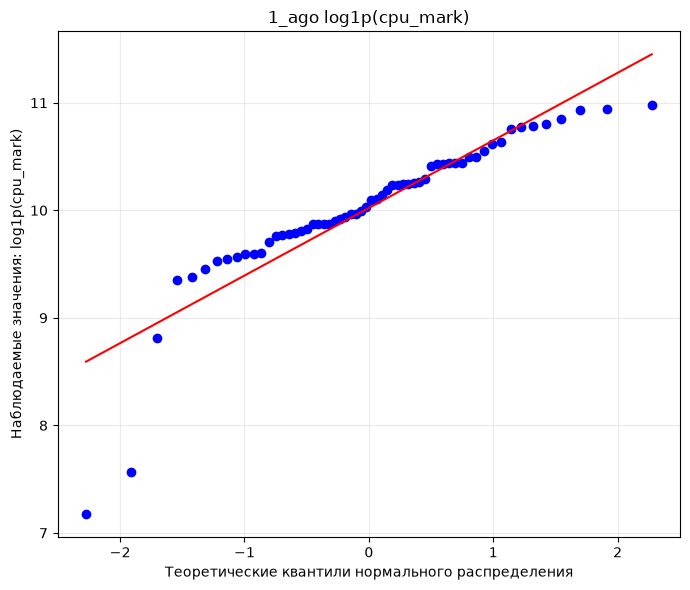

Q-Q plots будут построены для:
['cpu_mark']


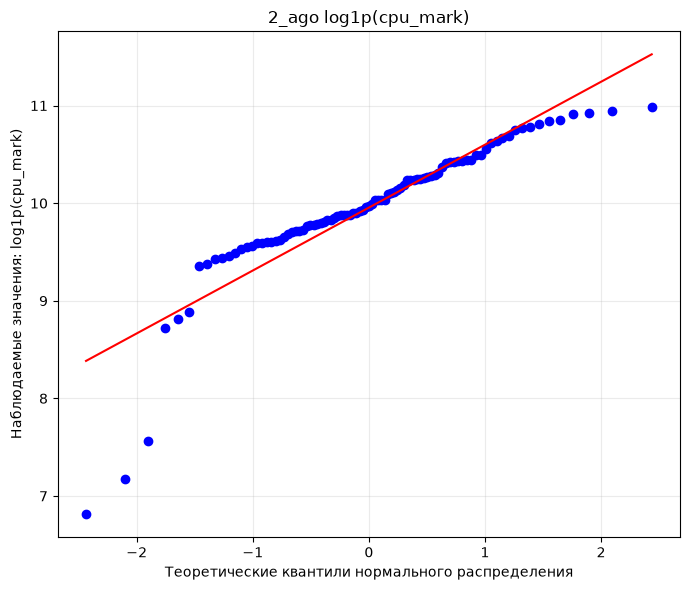

Q-Q plots будут построены для:
['cpu_mark']


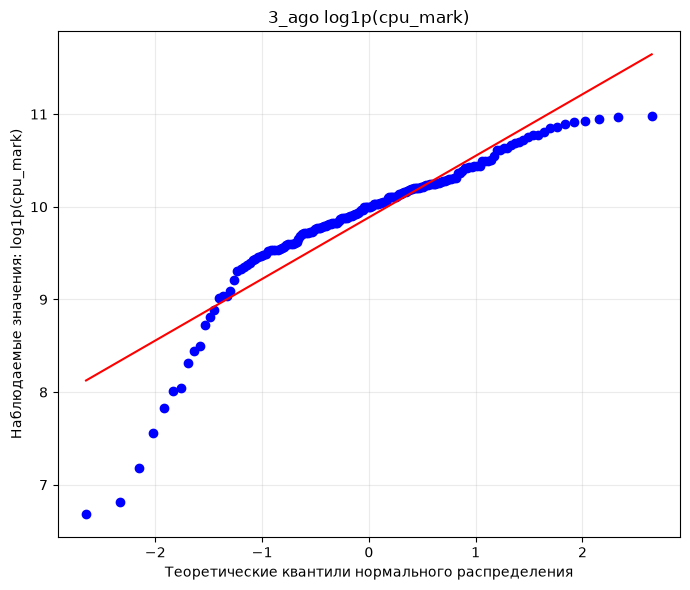

Q-Q plots будут построены для:
['cpu_mark']


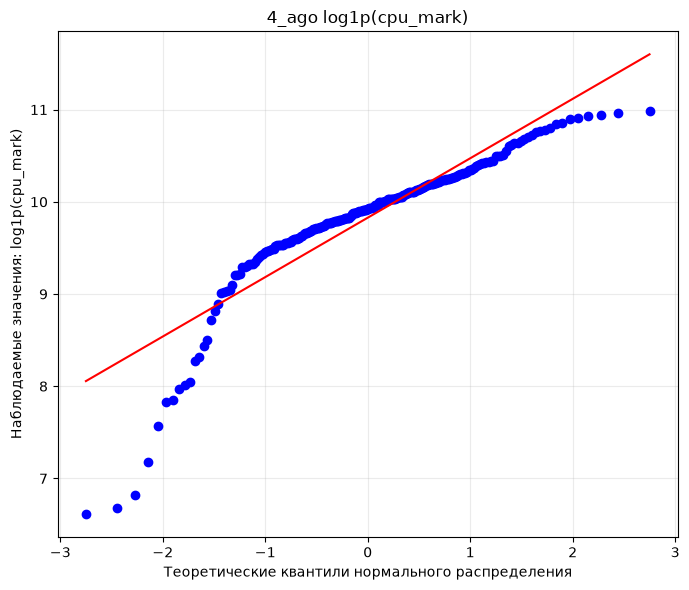

Q-Q plots будут построены для:
['cpu_mark']


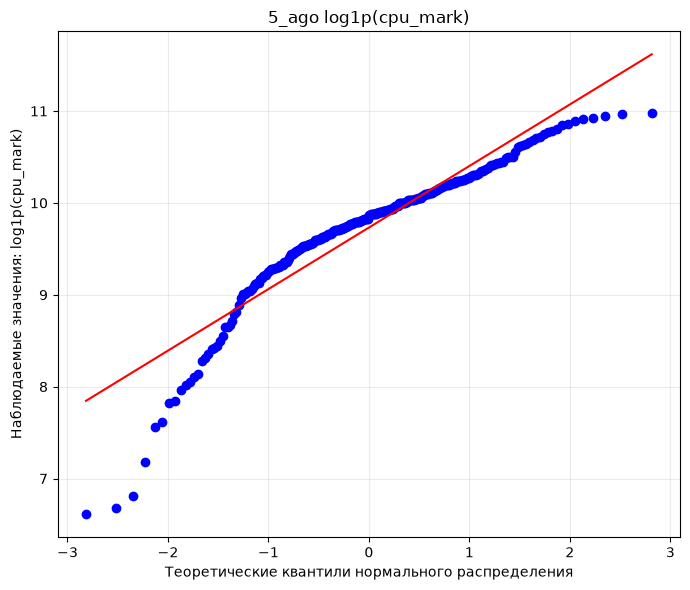

Q-Q plots будут построены для:
['cpu_mark']


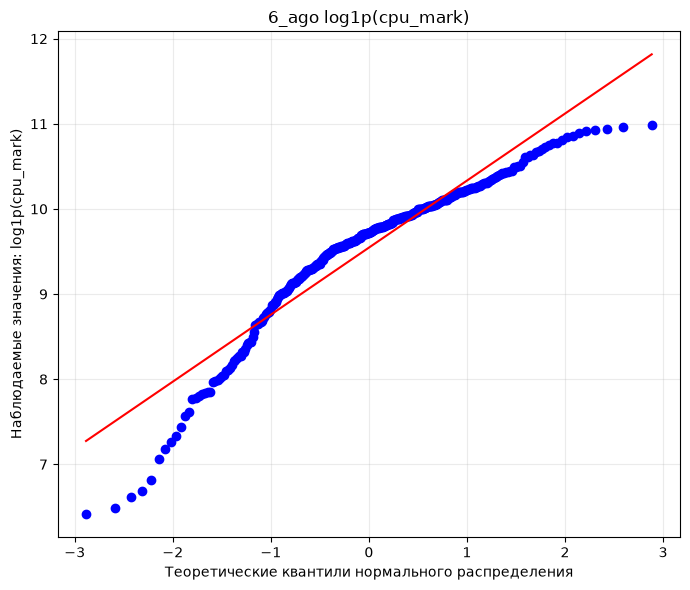

Q-Q plots будут построены для:
['cpu_mark']


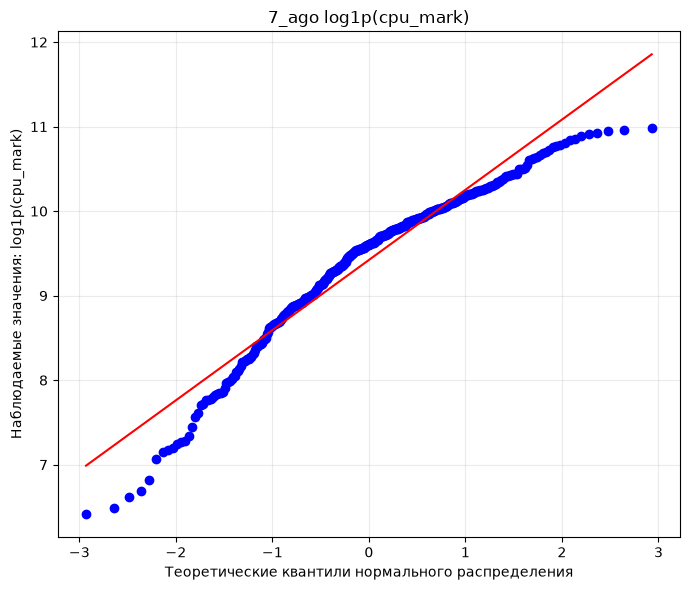

Q-Q plots будут построены для:
['cpu_mark']


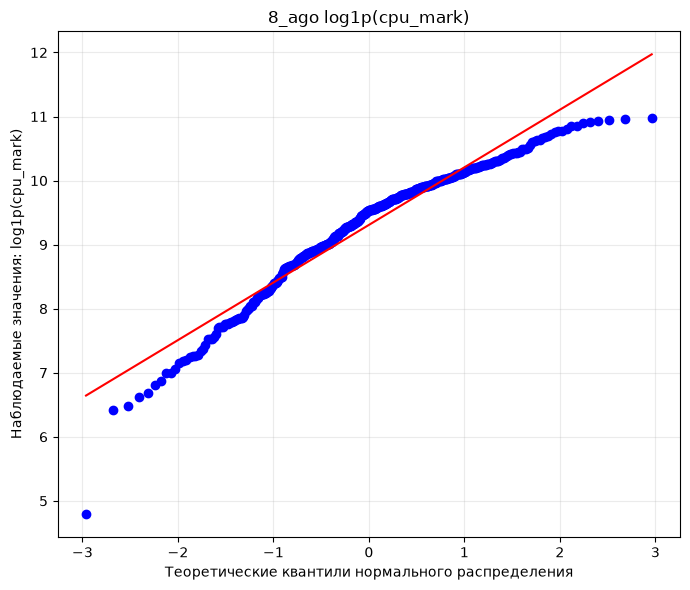

Q-Q plots будут построены для:
['cpu_mark']


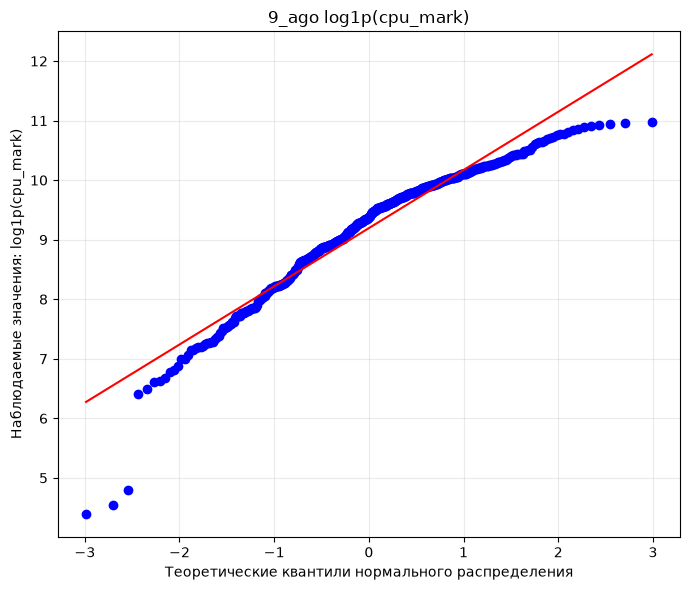

Q-Q plots будут построены для:
['cpu_mark']


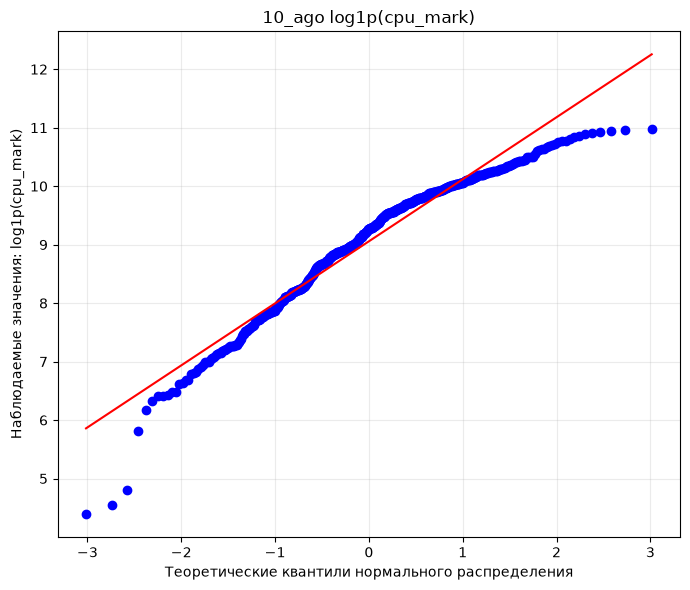

Q-Q plots будут построены для:
['cpu_mark']


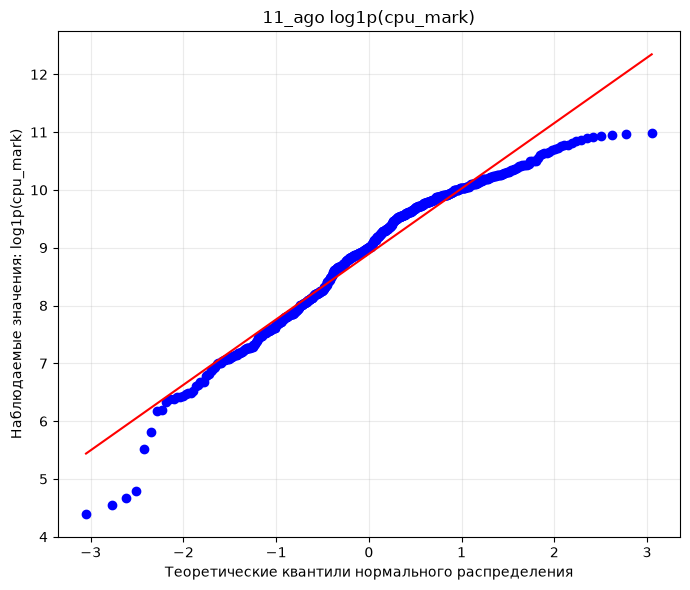

Q-Q plots будут построены для:
['cpu_mark']


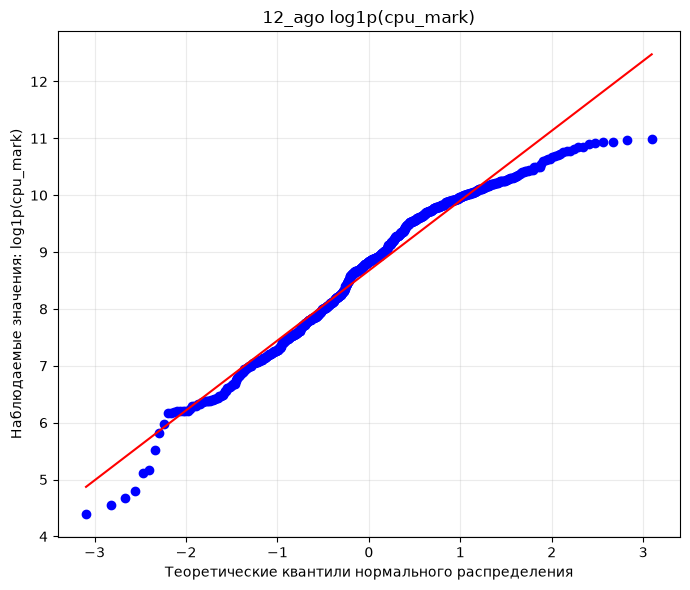

Q-Q plots будут построены для:
['cpu_mark']


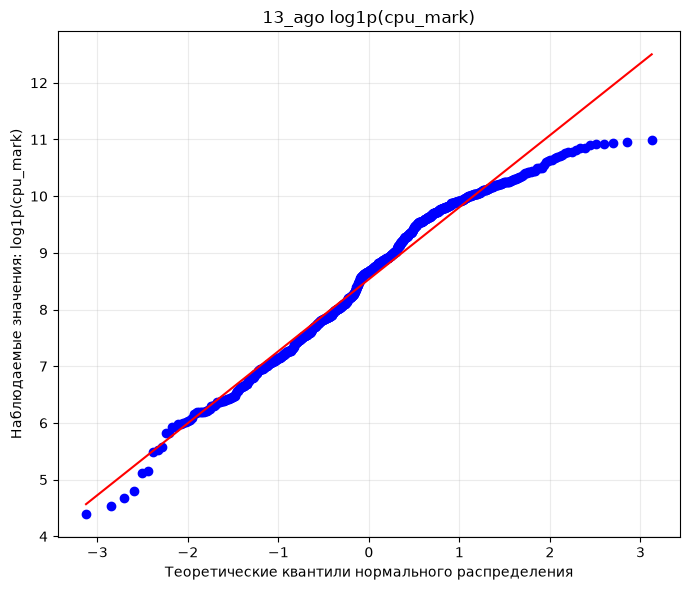

Q-Q plots будут построены для:
['cpu_mark']


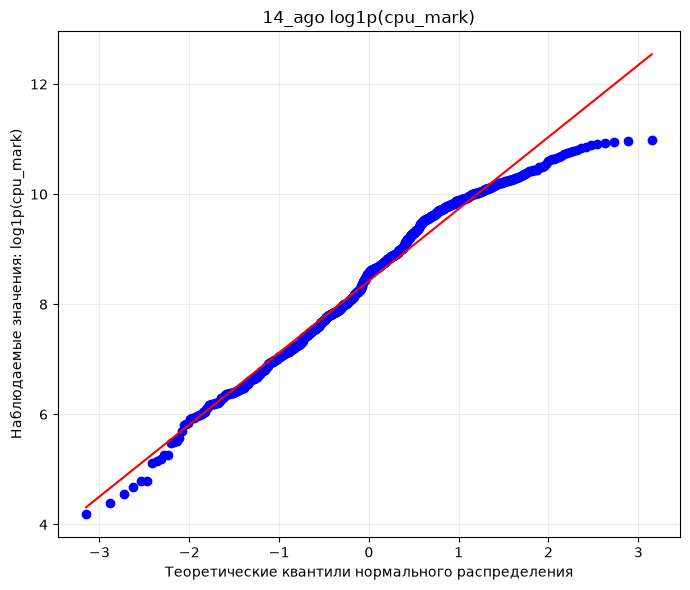

Q-Q plots будут построены для:
['cpu_mark']


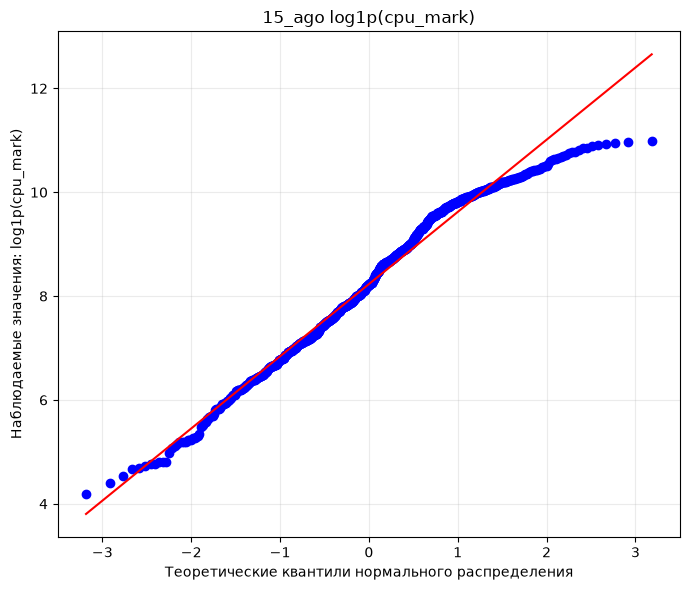

Q-Q plots будут построены для:
['cpu_mark']


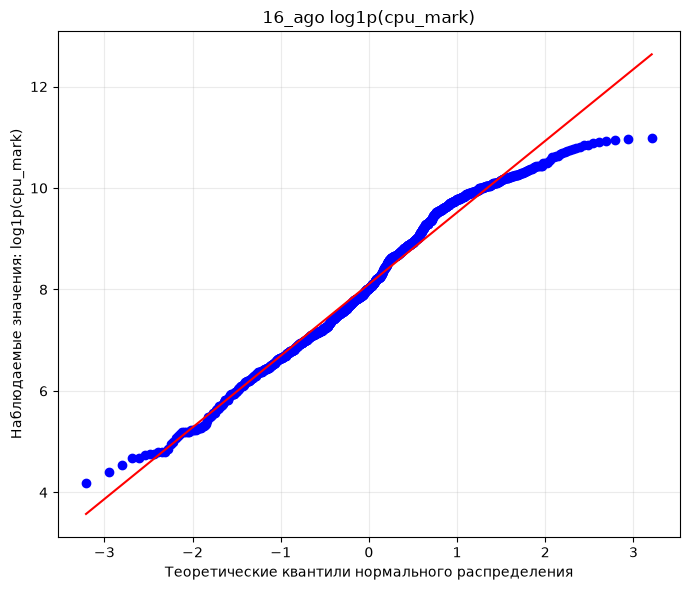

Q-Q plots будут построены для:
['cpu_mark']


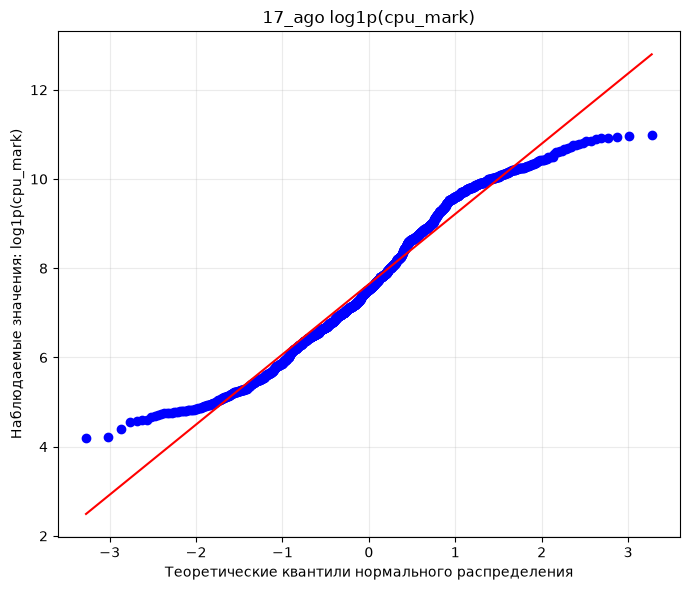

In [9]:
laptops_df_dict = dict()
for i in range(laptops.years_ago.min(), laptops.years_ago.max()):
    laptops_df_dict[f'{i}_ago'] = laptops[laptops['years_ago'] <= i]
    plot_qq(
        laptops_df_dict[f'{i}_ago'],
        columns=[
            'cpu_mark'
        ],
        log_columns=[
            "cpu_mark"
        ],
        title=f'{i}_ago log1p(cpu_mark)'
    )

Q-Q plots будут построены для:
['cpu_mark']


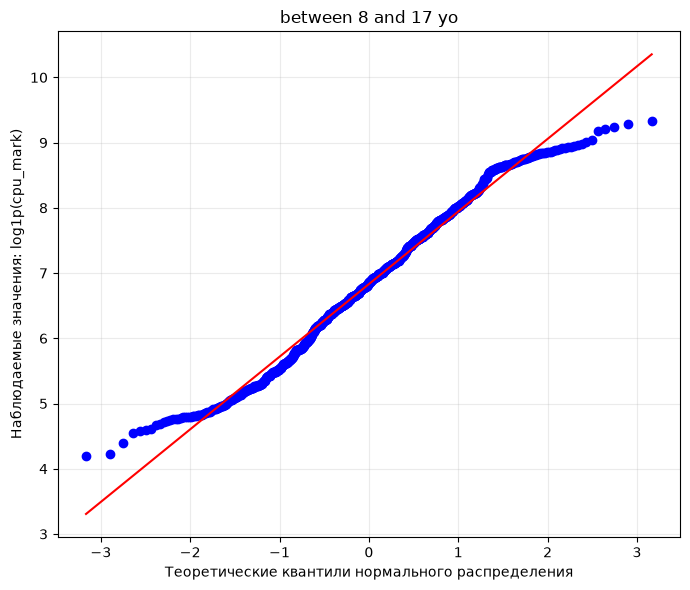

In [10]:
plot_qq(
    laptops[laptops['years_ago'].isin(range(8, 18))],
    columns=[
        'cpu_mark'
    ],
    log_columns=[
        "cpu_mark"
    ],
    title=f'between 8 and 17 yo'
)

<Axes: xlabel='cpu_mark', ylabel='Count'>

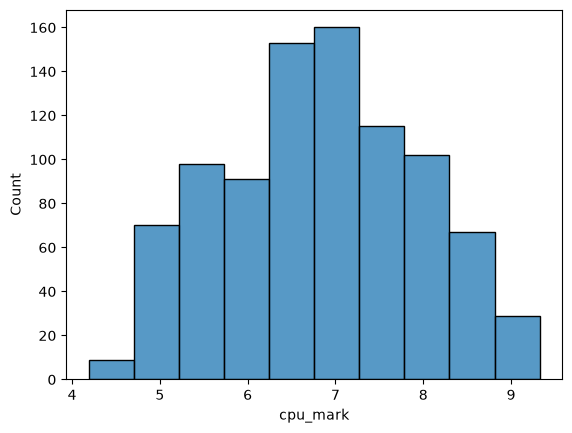

In [11]:
laptops_best = laptops[laptops['years_ago'].isin(range(8, 18))]
sns.histplot(np.log1p(laptops_best.cpu_mark), bins=10)

In [12]:
all_obj = pd.read_csv('final4.csv')

<Axes: xlabel='cpu_mark', ylabel='Count'>

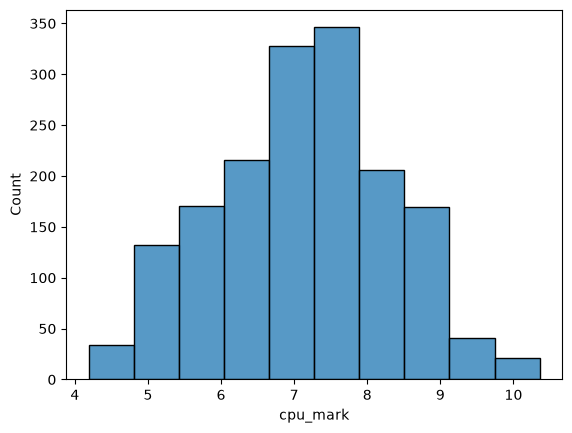

In [13]:
all_best = all_obj[all_obj['years_ago'].isin(range(8, 18))]
sns.histplot(np.log1p(all_best.cpu_mark), bins=10)

Q-Q plots будут построены для:
['cpu_mark']


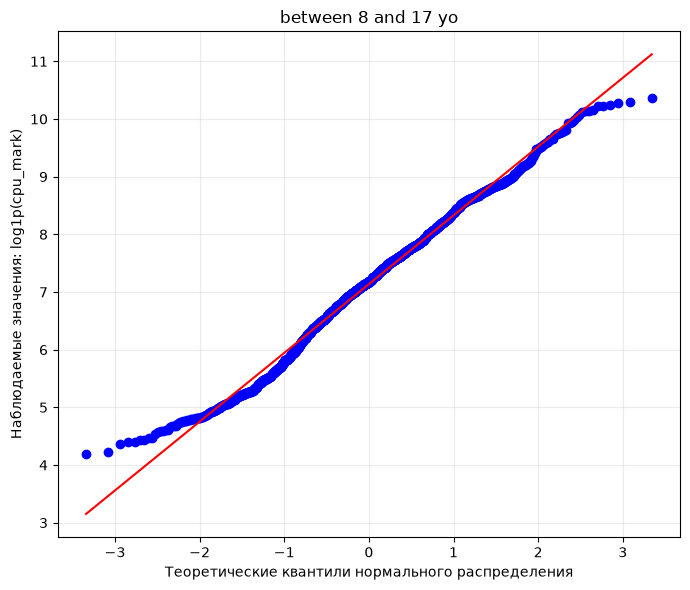

In [14]:
plot_qq(
    all_best[all_best['years_ago'].isin(range(8, 18))],
    columns=[
        'cpu_mark'
    ],
    log_columns=[
        "cpu_mark"
    ],
    title=f'between 8 and 17 yo'
)

In [15]:
weird = laptops[(np.log1p(laptops['cpu_mark']) < 10.4) & (np.log1p(laptops['cpu_mark']) > 9)]

In [16]:
weird.to_csv('weird.csv')

<Axes: xlabel='years_ago', ylabel='Count'>

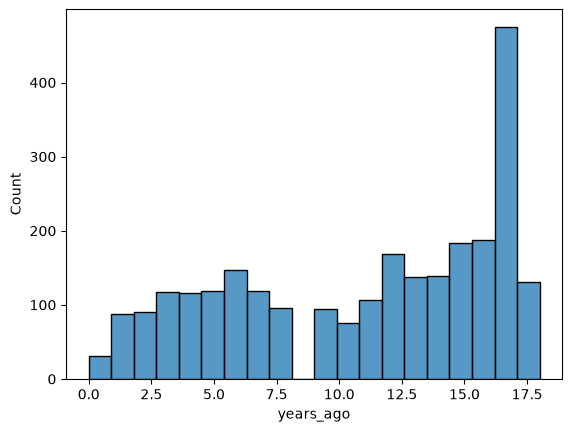

In [18]:
sns.histplot(all_obj['years_ago'], bins=20)

In [19]:
new = all_obj[all_obj['years_ago'] < 9]

Q-Q plots будут построены для:
['cpu_mark']


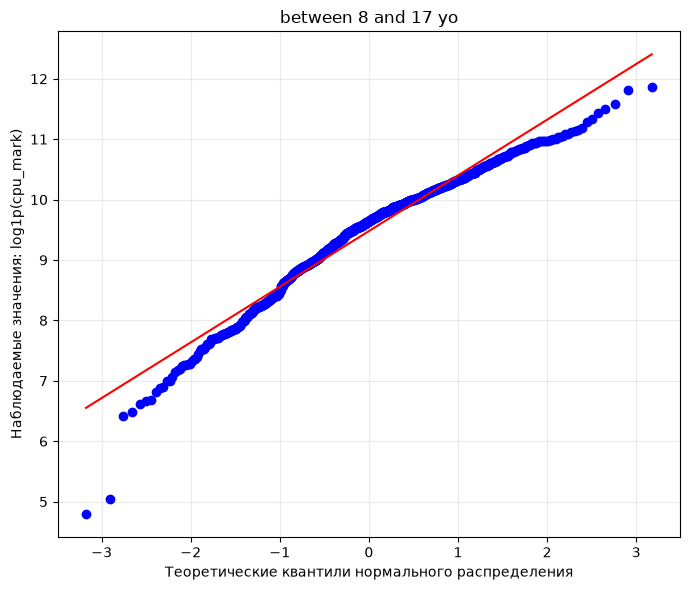

In [20]:
plot_qq(
    new,
    columns=[
        'cpu_mark'
    ],
    log_columns=[
        "cpu_mark"
    ],
    title=f'between 8 and 17 yo'
)

<Axes: xlabel='cpu_mark', ylabel='Count'>

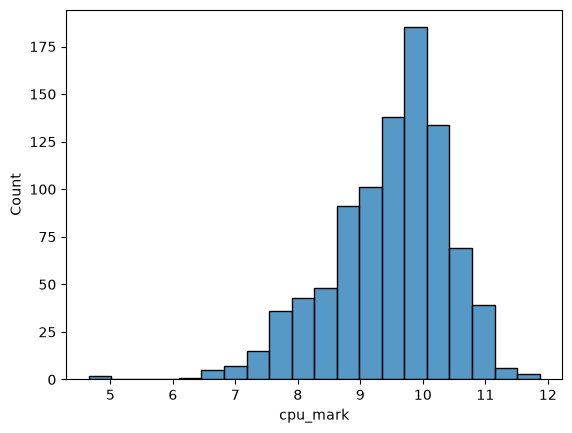

In [28]:
sns.histplot(np.log(new['cpu_mark'] - 15), bins=20)

<Axes: xlabel='cpu_mark', ylabel='Count'>

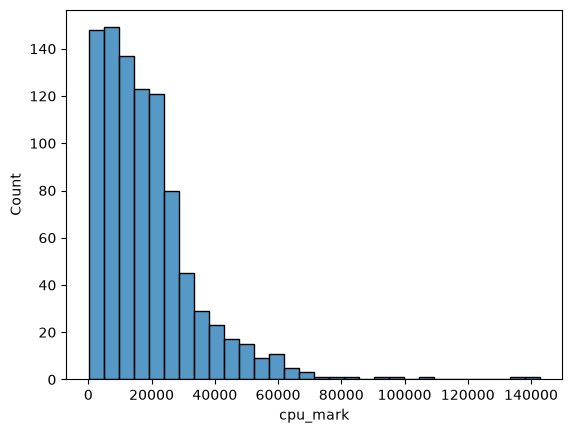

In [26]:
sns.histplot(new['cpu_mark'], bins=30)